# Partie 2 — Exercice 2 : Classification des fleurs Iris 🌸

**Objectif :** entraîner un réseau de neurones pour prédire l'espèce d'une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : **setosa, versicolor et virginica**.

Bibliothèques utilisées : `torch` et `scikit-learn`.

## 1. Charger et préparer les données

On sépare les données en **80 % entraînement** et **20 % test**.

Le `StandardScaler` est ajusté uniquement sur les données d'entraînement, puis appliqué aux données de test.

In [2]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


### Questions

**1. Que représentent les quatre colonnes de `X_train` ?**

Elles représentent les quatre mesures de chaque fleur : longueur du sépale, largeur du sépale, longueur du pétale et largeur du pétale.

**2. Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**

Parce que `CrossEntropyLoss` attend des classes représentées par des indices entiers.

**3. Pourquoi ne faut-il pas ajuster le `StandardScaler` sur les données de test ?**

Pour éviter une fuite d'information : les statistiques utilisées pour normaliser le test doivent provenir uniquement des données d'entraînement.

## 2. Construire le réseau

L'architecture demandée est :

`4 → couche cachée → 3`

La couche cachée utilise `ReLU`. La sortie contient 3 scores, un pour chaque espèce.

In [3]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


**Attention :** on n'ajoute pas de `Softmax` à la sortie. `CrossEntropyLoss` attend directement les scores bruts, appelés **logits**.

## 3. Entraîner le modèle

Pour cet exercice, chaque itération utilise toutes les données d'entraînement.

In [4]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # Remettre les gradients à zéro
    optimizer.zero_grad()

    # Calculer les scores prédits
    logits = model(X_train)

    # Calculer la perte
    loss = criterion(logits, y_train)

    # Calculer les gradients
    loss.backward()

    # Mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


## 4. Évaluer le classifieur

On utilise `model.eval()` et `torch.no_grad()` pour évaluer le modèle sur les données de test.

In [5]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # Classe ayant le score maximal
    predictions = logits.argmax(dim=1)

    # Proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


## 5. Courbe de perte

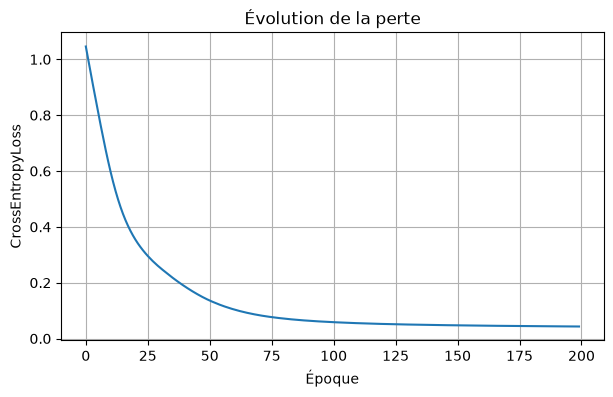

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("CrossEntropyLoss")
plt.title("Évolution de la perte")
plt.grid(True)
plt.show()

## 6. Matrice de confusion

Les lignes correspondent aux vraies classes et les colonnes aux classes prédites.

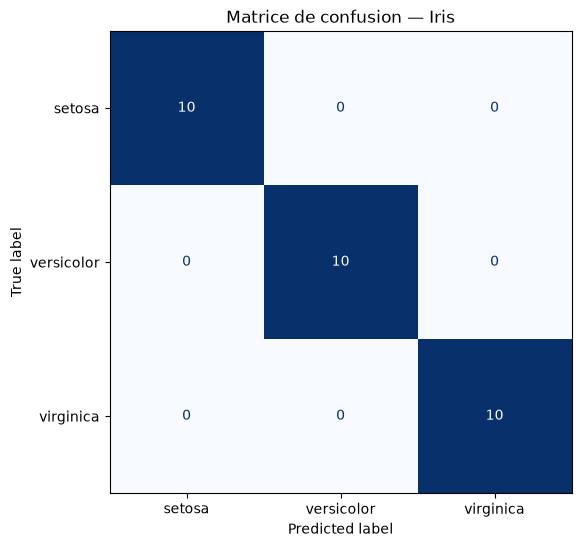

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test.numpy(), predictions.numpy())

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matrice de confusion — Iris")
plt.show()

## 7. Comparaison avec un modèle sans couche cachée

On compare le réseau précédent avec un modèle simple `nn.Linear(4, 3)`.

In [8]:
model_linear = nn.Linear(4, 3)

criterion_linear = nn.CrossEntropyLoss()
optimizer_linear = torch.optim.Adam(model_linear.parameters(), lr=0.01)

losses_linear = []

model_linear.train()

for epoch in range(200):
    optimizer_linear.zero_grad()

    logits_linear = model_linear(X_train)
    loss_linear = criterion_linear(logits_linear, y_train)

    loss_linear.backward()
    optimizer_linear.step()

    losses_linear.append(loss_linear.item())

model_linear.eval()

with torch.no_grad():
    predictions_linear = model_linear(X_test).argmax(dim=1)
    accuracy_linear = (predictions_linear == y_test).float().mean()

print(f"Accuracy avec couche cachée : {accuracy.item():.1%}")
print(f"Accuracy sans couche cachée : {accuracy_linear.item():.1%}")

Accuracy avec couche cachée : 100.0%
Accuracy sans couche cachée : 90.0%


### Interprétation

Le modèle `nn.Linear(4, 3)` est un classifieur linéaire. Le réseau avec une couche cachée et une activation `ReLU` peut apprendre une relation plus complexe entre les quatre mesures et les trois espèces.

L'accuracy exacte dépend de l'entraînement et des paramètres utilisés.

## 8. Prédire une nouvelle fleur

Nouvelle fleur :

`[5.1, 3.5, 1.4, 0.2]`

Il faut obligatoirement la normaliser avec **le même `scaler`** utilisé pour les données d'entraînement.

In [9]:
nouvelle_fleur = np.array([[5.1, 3.5, 1.4, 0.2]])

# Utiliser le même scaler
nouvelle_fleur_norm = scaler.transform(nouvelle_fleur)

# Convertir en tenseur
nouvelle_fleur_tensor = torch.tensor(
    nouvelle_fleur_norm,
    dtype=torch.float32
)

model.eval()

with torch.no_grad():
    logits_nouvelle = model(nouvelle_fleur_tensor)
    classe_predite = logits_nouvelle.argmax(dim=1).item()

print("Classe prédite :", classe_predite)
print("Espèce prédite :", iris.target_names[classe_predite])

Classe prédite : 0
Espèce prédite : setosa


### Réponse attendue

Pour les mesures `[5.1, 3.5, 1.4, 0.2]`, qui correspondent typiquement à une fleur **Iris setosa**, le modèle devrait prédire la classe `setosa` après normalisation.

# Résumé de l'exercice

- **Entrées :** 4 caractéristiques.
- **Classes :** 3 espèces (`setosa`, `versicolor`, `virginica`).
- **Normalisation :** `StandardScaler`.
- **Modèle :** `Linear(4,16) → ReLU → Linear(16,3)`.
- **Loss :** `CrossEntropyLoss`.
- **Optimiseur :** Adam avec `lr=0.01`.
- **Entraînement :** 200 époques.
- **Évaluation :** accuracy + matrice de confusion.
- **Prédiction :** nouvelle fleur après normalisation avec le même scaler.